# Step 5 — 两阶段 ZIP-RC predictor 训练

1. Stage 1：用 `correct`、KL=0 训练 intermediate predictor；
2. 用 intermediate model 给 train split 写入 denoised `value`；
3. Stage 2：用 `value`、KL=10 训练最终 ZIP-RC。

训练脚本会把每个 optimizer step 的 loss 写到 JSONL，本 Notebook 绘制 loss、KL 和学习率曲线。

In [4]:
from pathlib import Path
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents, Path("/content/ZIP-RC-Colab"), Path("/content/ZIP-RC")]
REPO = next(
    (path for path in candidates if (path / "notebooks" / "ziprc_notebook_utils.py").exists()),
    None,
)
if REPO is None:
    raise FileNotFoundError("找不到 ZIP-RC 仓库；请从仓库根目录或 notebooks/ 运行。")

if not Path("/content/mamba/envs/zip/bin/python").exists():
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
colab_python = Path("/content/mamba/envs/zip/bin/python")
if colab_python.exists():
    os.environ["ZIPRC_PYTHON"] = str(colab_python)

sys.path.insert(0, str(REPO / "notebooks"))
from ziprc_notebook_utils import *

CONFIG = load_config(REPO)
print("Repository:", REPO)
print("Experiment:", CONFIG["experiment_name"])
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES", "all"))

Repository: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab
Experiment: qwen3_0.6b_ziprc_small_validation
CUDA_VISIBLE_DEVICES: 1


In [5]:
RUN_STAGE_1 = True
train_path = REPO / CONFIG["paths"]["train"]
intermediate_model = REPO / CONFIG["paths"]["intermediate_model"]
stage1_metrics = REPO / CONFIG["paths"]["stage1_metrics"]
if RUN_STAGE_1:
    run_repo(
        REPO,
        "python3", "src/train_ziprc_joint_head.py",
        "--model-id", CONFIG["model_id"], "--data-path", train_path,
        "--weights-path", intermediate_model,
        "--distribution-token-id", CONFIG["distribution_token_id"],
        "--label-column", "correct", "--reward-values", 0.0, 1.0,
        "--kl-coefficient", 0.0,
        "--batch-size", CONFIG["batch_size"],
        "--gradient-accumulation-steps", CONFIG["gradient_accumulation_steps"],
        "--num-epochs", CONFIG["num_epochs"], "--max-steps", CONFIG["stage1_steps"],
        "--learning-rate", CONFIG["stage1_learning_rate"],
        "--max-length", CONFIG["train_max_length"], "--dtype", CONFIG["dtype"],
        "--metrics-path", stage1_metrics, "--log-every", 10, "--visualization-freq", 50,
    )

Progress checkpoint: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/progress/train_ziprc_joint_head__stage1.json
Running: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/bin/python src/train_ziprc_joint_head.py --model-id Qwen/Qwen3-0.6B --data-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train.parquet --weights-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/models/experiment_joint_correct --distribution-token-id 151669 --label-column correct --reward-values 0.0 1.0 --kl-coefficient 0.0 --batch-size 1 --gradient-accumulation-steps 8 --num-epochs 3 --max-steps 500 --learning-rate 0.0001 --max-length 4096 --dtype bfloat16 --metrics-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/metrics/stage1.jsonl --log-every 10 --visualization-freq 50
flash_attention_2 not available (FlashAttention2 has been toggled on, but it cannot be used due to the following error: the package flash_att

Train ZIP-RC:  10%|█         | 50/500 [elapsed 00:56, remaining 08:21]/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/lib/python3.10/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(



JOINT DISTRIBUTION VISUALIZATION - Step 50

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
002%000%
004%014%
004%018%
009%047%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%100%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
002%000%
003%014%
003%017%
008%052%


Ground Truth (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%100%




Train ZIP-RC:  20%|██        | 100/500 [elapsed 01:52, remaining 07:28]


JOINT DISTRIBUTION VISUALIZATION - Step 100

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
002%016%
006%022%
007%027%
006%014%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
100%000%
000%000%
000%000%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%001%
001%002%
012%083%


Ground Truth (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
100%000%




...


JOINT DISTRIBUTION VISUALIZATION - Step 450

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%001%
000%098%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%100%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
001%099%


Ground Truth (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%100%




Train ZIP-RC: 100%|██████████| 500/500 [elapsed 09:19, remaining 00:00]



JOINT DISTRIBUTION VISUALIZATION - Step 500

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
012%025%
008%041%
002%010%
000%001%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%100%
000%000%
000%000%
000%000%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%001%
010%089%


Ground Truth (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%000%
000%100%




[rank0]:[W930 16:59:28.962322528 ProcessGroupNCCL.cpp:1496] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


Command elapsed time: 9.5 minutes


In [6]:
RUN_VALUE_SCORING = True
train_value_path = REPO / CONFIG["paths"]["train_value"]
if RUN_VALUE_SCORING:
    run_repo(
        REPO,
        "python3", "src/score_with_ziprc_joint_head.py",
        "--model", intermediate_model, "--in-parquet", train_path,
        "--out-parquet", train_value_path,
        "--distribution-token-id", CONFIG["distribution_token_id"],
        "--num-length-bins", CONFIG["num_length_bins"],
        "--reward-values", 0.0, 1.0, "--last-k", 64,
        "--max-length", CONFIG["train_max_length"], "--batch-size", 1,
        "--num-workers", 0, "--dtype", CONFIG["dtype"],
    )

Progress checkpoint: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/progress/score_with_ziprc_joint_head__train_with_value.json
Running: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/bin/python src/score_with_ziprc_joint_head.py --model /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/models/experiment_joint_correct --in-parquet /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train.parquet --out-parquet /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train_with_value.parquet --distribution-token-id 151669 --num-length-bins 8 --reward-values 0.0 1.0 --last-k 64 --max-length 4096 --batch-size 1 --num-workers 0 --dtype bfloat16
ZIP: Label with joint-distribution (no vLLM)
  Model:   /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/models/experiment_joint_correct
  Input:   /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train.parquet
  Output:  /ssddata/hzhuaq/

Score trajectories: 100%|██████████| 3200/3200 [elapsed 01:30, remaining 00:00]


  Correlation with ground truth: 0.558
  Accuracy at threshold 0.5: 85.2%
✓ Wrote labeled parquet: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train_with_value.parquet
  rows: 3200 | missing values: 0
  elapsed: 90.9s
Command elapsed time: 1.6 minutes


In [7]:
RUN_STAGE_2 = True
final_model = REPO / CONFIG["paths"]["final_model"]
stage2_metrics = REPO / CONFIG["paths"]["stage2_metrics"]
if RUN_STAGE_2:
    run_repo(
        REPO,
        "python3", "src/train_ziprc_joint_head.py",
        "--model-id", CONFIG["model_id"], "--data-path", train_value_path,
        "--weights-path", final_model,
        "--distribution-token-id", CONFIG["distribution_token_id"],
        "--label-column", "value", "--reward-values", *CONFIG["reward_values"],
        "--kl-coefficient", 10.0,
        "--batch-size", CONFIG["batch_size"],
        "--gradient-accumulation-steps", CONFIG["gradient_accumulation_steps"],
        "--num-epochs", CONFIG["num_epochs"], "--max-steps", CONFIG["stage2_steps"],
        "--learning-rate", CONFIG["stage2_learning_rate"],
        "--max-length", CONFIG["train_max_length"], "--dtype", CONFIG["dtype"],
        "--metrics-path", stage2_metrics, "--log-every", 10, "--visualization-freq", 50,
    )

Progress checkpoint: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/progress/train_ziprc_joint_head__stage2.json
Running: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/bin/python src/train_ziprc_joint_head.py --model-id Qwen/Qwen3-0.6B --data-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/splits/train_with_value.parquet --weights-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/models/experiment_ziprc_final --distribution-token-id 151669 --label-column value --reward-values 0.0 0.16666666666666666 0.3333333333333333 0.5 0.6666666666666666 0.8333333333333334 1.0 --kl-coefficient 10.0 --batch-size 1 --gradient-accumulation-steps 8 --num-epochs 3 --max-steps 800 --learning-rate 5e-05 --max-length 4096 --dtype bfloat16 --metrics-path /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/metrics/stage2.jsonl --log-every 10 --visualization-freq 50
flash_attention_2 not available (FlashAttention2 has 

Train ZIP-RC:   6%|▋         | 50/800 [elapsed 01:11, remaining 17:50]/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/lib/python3.10/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(



JOINT DISTRIBUTION VISUALIZATION - Step 50

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%001%001%001%001%001%001%
000%001%001%001%001%001%001%
000%001%001%001%001%001%001%
000%001%001%001%001%001%001%
000%002%001%002%002%005%001%
000%000%001%001%001%010%002%
000%000%001%001%001%011%005%
000%000%001%001%002%011%013%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%100%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
002%001%001%001%001%001%001%
002%001%001%001%001%001%001%
002%001%001%001%001%001%001%
002%001%001%001%001%001%001%
004%001%001%001%001%003%001%
004%004%001%001%001%006%001%
003%003%001%001%001%007%004%
003%00

Train ZIP-RC:  12%|█▎        | 100/800 [elapsed 02:22, remaining 16:38]


JOINT DISTRIBUTION VISUALIZATION - Step 100

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%002%001%001%001%004%000%
000%000%000%001%001%022%001%
000%000%000%000%000%021%006%
000%000%000%000%001%021%014%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%100%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
001%001%000%001%001%002%000%
000%001%000%000%000%008%001%
000%000%000%000%000%009%005%
000%0

...


JOINT DISTRIBUTION VISUALIZATION - Step 750

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
001%003%001%001%001%006%000%
000%000%001%001%001%031%001%
000%000%000%000%001%031%002%
000%000%000%000%001%015%001%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%100%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%001%000%
000%0

Train ZIP-RC: 100%|██████████| 800/800 [elapsed 18:59, remaining 00:00]



JOINT DISTRIBUTION VISUALIZATION - Step 800

Predicted (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
003%007%002%002%002%024%000%
000%000%000%000%000%043%000%
000%000%000%000%000%013%000%
000%000%000%000%000%001%000%


Ground Truth (first) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%100%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%


Predicted (last) joint distribution (length high→low x value low→high)
(raw probabilities)
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
000%000%000%000%000%000%000%
003%001%000%000%000%000%000%
017%015%001%001%001%000%000%
012%014%001%001%001%000%000%
016%0

[rank0]:[W930 17:42:07.944661842 ProcessGroupNCCL.cpp:1496] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


Command elapsed time: 19.2 minutes


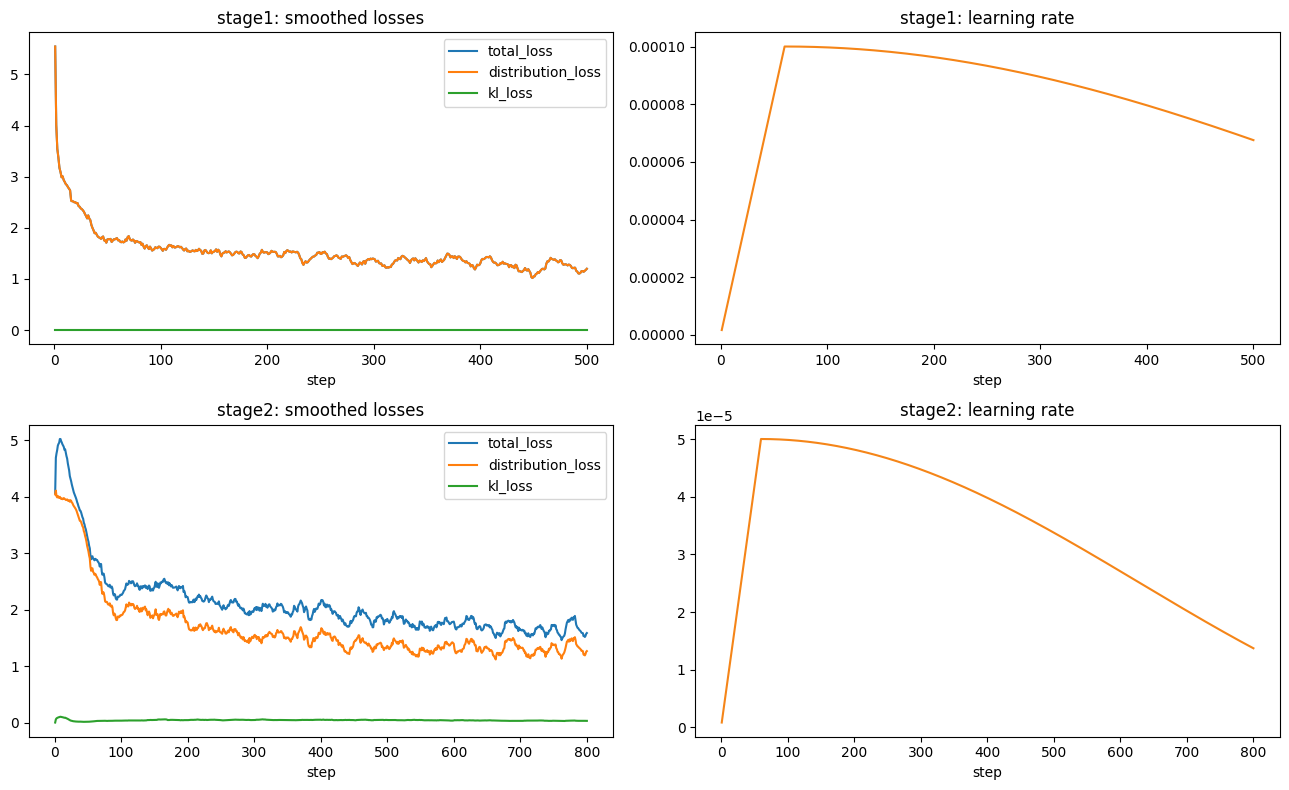

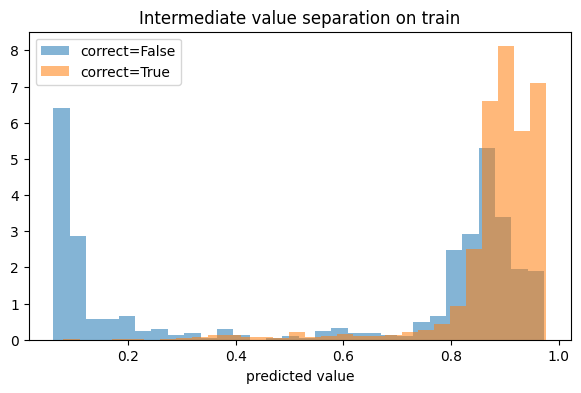

,类型,检查项,状态,说明
0,operational,Stage 1 模型已保存,✅ 通过,/ssddata/hzhuaq/Developer/github.com/wtree101/...
1,operational,Stage 2 模型已保存,✅ 通过,/ssddata/hzhuaq/Developer/github.com/wtree101/...
2,operational,训练 metrics 完整,✅ 通过,steps=500/800
3,operational,Loss 全部有限,✅ 通过,no NaN/Inf
4,scientific,Stage 1 distribution loss 下降,✅ 通过,2.057 → 1.221
5,scientific,Stage 2 total loss 下降,✅ 通过,3.109 → 1.643
6,scientific,Value 非常数,✅ 通过,std=0.2291


PosixPath('/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/stage_reports/05_predictor_training.json')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

histories = {"stage1": read_jsonl(stage1_metrics), "stage2": read_jsonl(stage2_metrics)}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (name, history) in enumerate(histories.items()):
    smooth = history.set_index("step")[["total_loss", "distribution_loss", "kl_loss"]].rolling(15, min_periods=1).mean()
    smooth.plot(ax=axes[row, 0])
    axes[row, 0].set_title(f"{name}: smoothed losses")
    history.plot(x="step", y="learning_rate", ax=axes[row, 1], legend=False, color="#f58518")
    axes[row, 1].set_title(f"{name}: learning rate")
plt.tight_layout()
plt.show()

stage1_start, stage1_end = rolling_edges(histories["stage1"]["distribution_loss"])
stage2_start, stage2_end = rolling_edges(histories["stage2"]["total_loss"])
value_df = pd.read_parquet(train_value_path)
value_std = float(value_df["value"].std())

fig, ax = plt.subplots(figsize=(7, 4))
for label, group in value_df.groupby("correct"):
    ax.hist(group["value"].dropna(), bins=30, alpha=.55, density=True, label=f"correct={label}")
ax.set(title="Intermediate value separation on train", xlabel="predicted value")
ax.legend()
plt.show()

checks = [
    gate("Stage 1 模型已保存", model_artifacts_exist(intermediate_model), str(intermediate_model)),
    gate("Stage 2 模型已保存", model_artifacts_exist(final_model), str(final_model)),
    gate("训练 metrics 完整", len(histories["stage1"]) >= 50 and len(histories["stage2"]) >= 50, f"steps={len(histories['stage1'])}/{len(histories['stage2'])}"),
    gate("Loss 全部有限", all(np.isfinite(history[["total_loss", "distribution_loss", "kl_loss"]]).all().all() for history in histories.values()), "no NaN/Inf"),
    gate("Stage 1 distribution loss 下降", stage1_end < stage1_start, f"{stage1_start:.3f} → {stage1_end:.3f}", kind="scientific"),
    gate("Stage 2 total loss 下降", stage2_end < stage2_start, f"{stage2_start:.3f} → {stage2_end:.3f}", kind="scientific"),
    gate("Value 非常数", value_std >= .01, f"std={value_std:.4f}", kind="scientific"),
]
display(gate_frame(checks))
save_stage_report(REPO, "05_predictor_training", checks, {"stage1_loss_start": stage1_start, "stage1_loss_end": stage1_end, "stage2_loss_start": stage2_start, "stage2_loss_end": stage2_end, "value_std": value_std})

In [9]:
bad_confident = value_df[
    (~value_df["correct"]) &
    (value_df["value"] >= 0.8)
].sort_values("value", ascending=False)

print("high-confidence wrong:", len(bad_confident))

display(
    bad_confident[
        ["prompt", "answer", "response", "value", "length", "finished"]
    ].head(20)
)

high-confidence wrong: 367


,prompt,answer,response,value,length,finished
292,"Charlie owns one flute, two horns, and a harp....","Charlie owns one flute, two horns, and a harp ...",We are told the following:\n\n- **Charlie** ow...,0.972772,235,True
709,Grant decided to sell his baseball gear since ...,The baseball glove was originally $30 and he a...,Let's calculate the total amount of money Gran...,0.972382,147,True
748,John has to restring 3 basses with 4 strings e...,The basses take 3*4=<<3*4=12>>12 strings\nHe r...,We are told:\n\n- John restring **3 basses** w...,0.971504,296,True
2932,Fatima has a piece of cloth that is 100 square...,The first cut will result in 100 / 2 = <<100/2...,Fatima has a cloth that is **100 square inches...,0.970681,116,True
1477,"Sally bought 3 photograph frames, each costing...",She bought the frames for 3 × $3 = $<<3*3=9>>9...,"Sally bought 3 frames, each costing **$3**, an...",0.970672,72,True
450,3 lions and 2 rhinos escape from the zoo. If ...,They had to recover 3+2=<<3+2=5>>5 animals\nSo...,We are told:\n\n- There are **3 lions and 2 rh...,0.970253,119,True
2690,Carlson bought land that cost $8000 and additi...,Carlson bought land that cost $20 per square m...,We are given the following information:\n\n- C...,0.970020,249,True
3159,Cherry put up a delivery service. She charges ...,Cherry earns $2.50 x 4= $<<2.5*4=10>>10 after ...,"First, let's figure out how many cargo deliver...",0.969981,280,True
2862,Cyrus has been contracted to write a 500 page ...,On the second day he wrote twice the amount as...,Cyrus starts with:\n\n- Day 1: 25 pages \n- D...,0.967969,168,True
1745,John and James decided to have a dance-off. J...,John dances 3+5=<<3+5=8>>8 hours\nJohn's total...,Let's break down the problem step by step.\n\n...,0.967929,221,True
